In [1]:
from picamera2 import Picamera2

picam2 = Picamera2()
picam2.preview_configuration.main.size = (640, 480)
picam2.preview_configuration.main.format = "RGB888"
picam2.configure("preview")
picam2.start()

frame = picam2.capture_array()
print("Captured frame shape:", frame.shape)

picam2.close()

[0:06:20.708698971] [3373]  INFO IPAManager ipa_manager.cpp:137 libcamera is not installed. Adding '/home/anatolii/libcamera/build/src/ipa' to the IPA search path
[0:06:20.709676230] [3373]  INFO Camera camera_manager.cpp:327 libcamera v0.4.0+53-29156679
[0:06:20.736954481] [3406]  INFO RPI pisp.cpp:720 libpisp version v1.0.7 28196ed6edcf 06-04-2025 (11:57:23)
[0:06:20.740212220] [3406]  INFO IPAProxy ipa_proxy.cpp:134 libcamera is not installed. Loading IPA configuration from '/home/anatolii/libcamera/src/ipa/rpi/pisp/data'
[0:06:20.749881199] [3406]  INFO RPI pisp.cpp:1179 Registered camera /base/axi/pcie@120000/rp1/i2c@88000/imx219@10 to CFE device /dev/media1 and ISP device /dev/media0 using PiSP variant BCM2712_C0
[0:06:20.749959736] [3406]  INFO RPI pisp.cpp:720 libpisp version v1.0.7 28196ed6edcf 06-04-2025 (11:57:23)
[0:06:20.752062994] [3406]  INFO IPAProxy ipa_proxy.cpp:134 libcamera is not installed. Loading IPA configuration from '/home/anatolii/libcamera/src/ipa/rpi/pisp/d

Captured frame shape: (480, 640, 3)


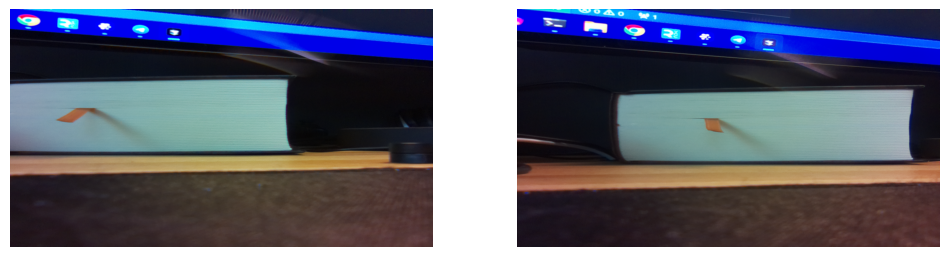

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time
from picamera2 import Picamera2
import cv2

# Initialize both cameras
picam0 = Picamera2(0)
picam1 = Picamera2(1)

# Configure both cameras
width = 1920
height = 1080
for cam in [picam0, picam1]:
    cam.video_configuration.main.size = (width, height)
    cam.video_configuration.main.format = "RGB888"
    cam.configure("video")
    cam.start()

# Create figure with two subplots side by side
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))

# Initialize images with dummy frames
im0 = ax0.imshow(np.zeros((height, width, 3), dtype=np.uint8))
im1 = ax1.imshow(np.zeros((height, width, 3), dtype=np.uint8))
ax0.axis("off")
ax1.axis("off")

# Display the figure in Jupyter
display(fig)

while True:
    try:
        # Capture frames from both cameras
        frame0 = picam0.capture_array()
        frame1 = picam1.capture_array()

        frame0 = cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB)
        frame1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB)

        # Update both images
        im0.set_data(frame0)
        im1.set_data(frame1)
        
        # Clear and redisplay the figure
        clear_output(wait=True)
        display(fig)
        
    except KeyboardInterrupt:
        break

# Clean up
picam0.close()
picam1.close()

In [2]:
# Clean up
picam0.close()
picam1.close()